# 04 — Primera red neuronal: Dense / MLP

**Pregunta:** ¿qué aprende una red que ve los píxeles de una prenda, pero no incorpora convoluciones?

Partimos de las mismas fotografías y particiones de 02–03. Entrenamos una red pequeña desde cero y observamos **cómo aprende, dónde se equivoca y qué cambia al añadir dropout**. La prioridad es comprender el proceso; no conseguir la mayor accuracy posible.

**Cómo leerlo:** cada sección explica primero la idea, después ejecuta el paso y finalmente interpreta su salida. Si solo quieres seguir el razonamiento, lee los textos, tablas y gráficos. El código reutilizable vive en `src/models/dense.py` y `src/training/dense_experiment.py`.

> **Estado y alcance.** Las salidas guardadas corresponden a la ejecución real del notebook. Se distingue el baseline de la única ablación realizada: dropout. La comparación con CNN y el resto de arquitecturas se harán después; este notebook no las da por resueltas.

## 1. Qué vamos a comprobar

Una **Dense** o capa totalmente conectada multiplica cada entrada por un peso y suma un sesgo. **MLP** es una red que combina varias de esas capas con activaciones no lineales.

1. Establecer un baseline neuronal reproducible con tres semillas.
2. Observar las curvas de train y validation para detectar dificultades de aprendizaje o sobreajuste.
3. Contrastar **sin dropout frente a dropout 0,30**, manteniendo las demás decisiones.
4. Comparar con las referencias clásicas de 03 e inspeccionar errores por clase.

La hipótesis H1 completa —Dense frente a CNN con presupuesto comparable— permanece abierta hasta ejecutar 05. No deducimos de antemano cuál ganará.

**Mini diccionario:** *época* = una pasada por train; *batch* = grupo de imágenes usado para actualizar pesos; *semilla* = controla la aleatoriedad; *logit* = puntuación sin normalizar por clase; *checkpoint* = pesos guardados de una época concreta.

## 2. Entorno local y diseño fijado antes de entrenar

Usamos CPU y cuatro hilos. No hace falta una GPU potente. La configuración está registrada en `config/dense_baseline_v1.json`, complementando el protocolo general. El entrenamiento usa **Adam, entropía cruzada sin pesos de clase y sin aumentos**.

Para repetirlo, selecciona el kernel **Python (Fashion Vision DL local)** de `.venv`. Instalación reproducible: `python -m venv --system-site-packages .venv`, después `.venv/Scripts/python -m pip install -r requirements-dl.txt`. La instalación ejecutada aquí utiliza la rueda CPU oficial de PyTorch. El README detalla el comando y el kernel.

In [1]:
from pathlib import Path
import sys, json, inspect, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown, Code
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/data/local_dataset.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.models.dense import DenseClassifier, parameter_count
from src.training.dense_experiment import (
    load_context, prepare_arrays, normalized_tensors, run_or_load,
    model_from_config, train_epoch, SelectionState, grouped_intervals, sha256,
)
from src.visualization.style import apply_style, display_es, format_number as number, format_percent as percent
from src.visualization.dense import (
    input_figure, curves_figure, dropout_figure, confusion_figure,
    per_class_figure, errors_figure, weight_figure, activation_figure,
)
apply_style()
context = load_context(ROOT)
config = context['config']
torch.set_num_threads(config['training']['threads'])
torch.use_deterministic_algorithms(True)
display_es(pd.DataFrame({
    'Decisión': ['PyTorch', 'Dispositivo', 'Hilos CPU', 'Semillas', 'Batch', 'Máximo épocas', 'Paciencia', 'Learning rate'],
    'Valor': [torch.__version__, 'CPU', 4, '42, 123 y 2026', 32, 30, 5, '0,001'],
}))

,Decisión,Valor
0,PyTorch,2.7.1+cpu
1,Dispositivo,CPU
2,Hilos CPU,4
3,Semillas,"42, 123 y 2026"
4,Batch,32
5,Máximo épocas,30
6,Paciencia,5
7,Learning rate,"0,001"


## 3. Datos y protección frente a fugas

Heredamos la publicación de 02: doce clases, hasta 1.500 imágenes por clase y separación por grupos de productos relacionados. **Una variante del mismo producto no puede aparecer en train y validation.** También comprobamos la separación de hashes de píxeles y la integridad del manifiesto.

Leemos metadatos de las tres particiones para verificar su separación. Después solo abrimos **fotografías de train y validation**. Conocer el número de ejemplos de test no significa utilizar sus imágenes para ajustar el modelo.

El dataset es una muestra equilibrada exploratoria. Estas métricas no estiman directamente el rendimiento sobre la distribución natural del catálogo.

In [2]:
rows = context['rows']
names = context['names']
display(Markdown(f"**Publicación:** `{context['run'].name}`. Manifiesto verificado por SHA-256."))
split_table = pd.DataFrame({
    'Partición': ['train', 'validation', 'test'],
    'Imágenes': [context['split_counts'][s] for s in ['train', 'validation', 'test']],
    'Uso aquí': ['Aprender pesos y normalización', 'Parada, checkpoint y análisis', 'Reservado; no se abren fotografías'],
})
display_es(split_table)
count_rows = pd.concat(rows.values(), ignore_index=True)
display_es(pd.crosstab(count_rows.label, count_rows.split).reindex(names))
assert set(rows['train'].group_id).isdisjoint(rows['validation'].group_id)
print('Controles superados: grupos, productos, píxeles, etiquetas y hashes del manifiesto.')

**Publicación:** `20261119T140252-527f781b`. Manifiesto verificado por SHA-256.

,Partición,Imágenes,Uso aquí
0,train,12.486,Aprender pesos y normalización
1,validation,2.898,"Parada, checkpoint y análisis"
2,test,2.616,Reservado; no se abren fotografías


split,train,validation
label,,
Blouse,1.021,222
Cardigan,1.061,232
Dress,1.057,227
Hoodie,1.053,221
Jacket,1.047,226
Shirt,1.007,245
Shorts,1.070,230
Skirt,1.040,243
Sweater,1.032,237


Controles superados: grupos, productos, píxeles, etiquetas y hashes del manifiesto.


## 4. De la fotografía a los números

Las imágenes se guardan a 224×224, pero la Dense recibe **RGB64**: 3 × 64 × 64 = **12.288 valores**. A 224×224 serían 150.528 entradas. Reducimos el coste sin cambiar qué productos utiliza cada partición ni la imagen preparada de origen.

La reducción usa Lanczos y conserva el encuadre cuadrado preparado en 02. No quitamos fondos ni realizamos una limpieza nueva dentro de este experimento. Se pierde detalle al reducir: es una limitación declarada.

Primero comprobamos el hash de cada JPEG de train y validation. Guardamos una caché local de arrays para no decodificarlos de nuevo en cada época. **La caché no es una nueva versión del dataset.**

train: 4.000 imágenes verificadas


train: 8.000 imágenes verificadas


train: 12.000 imágenes verificadas


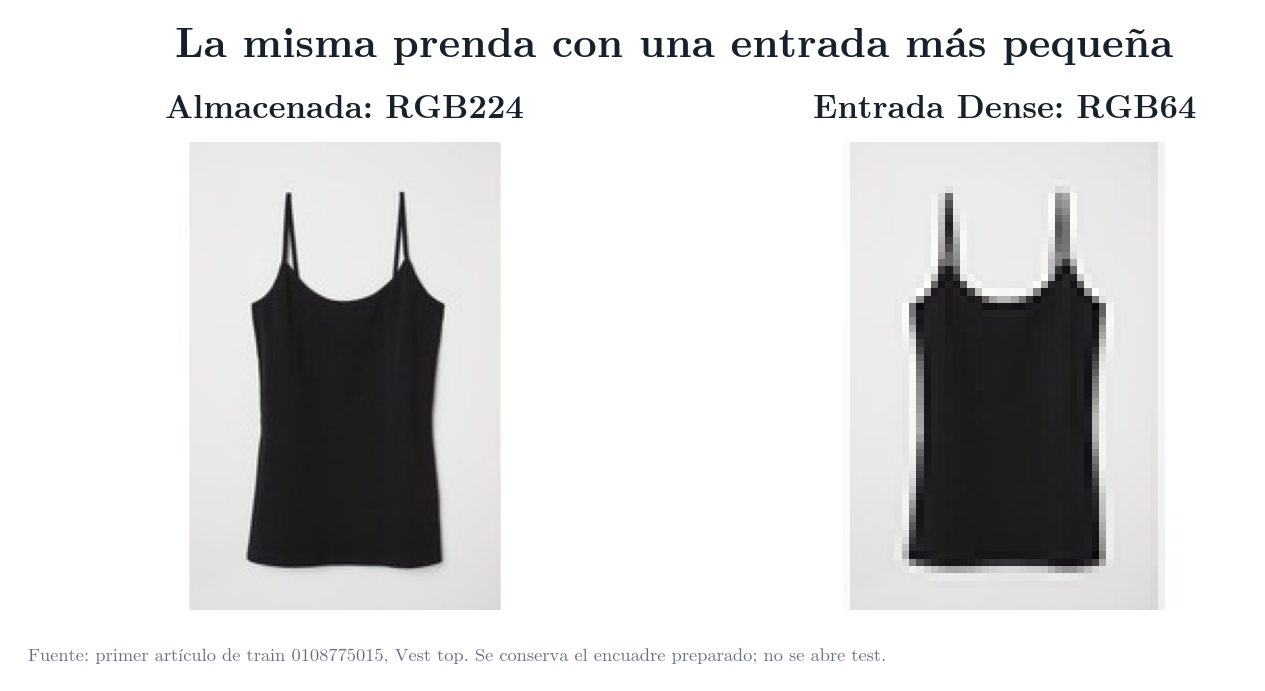

Preparación/verificación en esta ejecución: **17,4 s**. La duración cambia si existe caché.

In [3]:
prepared_at = time.perf_counter()
raw, normalization = prepare_arrays(context)
preparation_seconds = time.perf_counter() - prepared_at
input_figure(context, raw)
plt.show()
display(Markdown(f"Preparación/verificación en esta ejecución: **{number(preparation_seconds, 1)} s**. La duración cambia si existe caché."))

### Normalizar usando solo train

Dividimos los píxeles entre 255 para llevarlos a [0,1]. Después restamos la media de cada canal y dividimos por su desviación típica: **z = (x − media_train) / std_train**.

Calculamos las estadísticas **después de reducir a 64×64 y solo con train**. Aplicamos esos mismos valores a validation. Usar estadísticas de validation o test para preparar train introduciría información ajena al entrenamiento. Normalización de entrada no es lo mismo que BatchNorm; este modelo no incluye BatchNorm.

In [4]:
tensors = normalized_tensors(raw, normalization)
normalization_table = pd.DataFrame({
    'Canal': ['R', 'G', 'B'], 'Media train RGB64': normalization['mean'],
    'Desviación train RGB64': normalization['std'],
})
display_es(normalization_table)
channel_checks = []
for channel, label in enumerate(['R', 'G', 'B']):
    values = tensors['train'][:, channel]
    channel_checks.append({'Canal': label, 'Media normalizada train': float(values.mean()),
                           'Desviación normalizada train': float(values.std(unbiased=False))})
display_es(pd.DataFrame(channel_checks))
assert max(abs(r['Media normalizada train']) for r in channel_checks) < 1e-4
assert max(abs(r['Desviación normalizada train']-1) for r in channel_checks) < 1e-4
assert set(tensors) == {'train', 'validation'}
display(Markdown(f"**Forma de un batch:** `{tuple(tensors['train'][:32].shape)}` = imágenes × canales × alto × ancho."))

,Canal,Media train RGB64,Desviación train RGB64
0,R,"0,826","0,262"
1,G,"0,811","0,273"
2,B,"0,809","0,27"


,Canal,Media normalizada train,Desviación normalizada train
0,R,-0,1
1,G,-0,1
2,B,0,1


**Forma de un batch:** `(32, 3, 64, 64)` = imágenes × canales × alto × ancho.

## 5. La red, paso a paso

La arquitectura es **Flatten → Dense(80) → ReLU → Dense(32) → ReLU → Dense(12)**.

- **Flatten** ordena todos los píxeles en un vector; no aprende parámetros. Mantiene qué número ocupa cada posición, pero no incorpora filtros locales ni pesos compartidos como una CNN.
- **ReLU** devuelve el valor si es positivo y cero si es negativo. Aporta la no linealidad: sin ella, encadenar capas lineales equivaldría a una sola transformación lineal.
- La salida contiene **doce logits**, uno por clase. Para mostrar probabilidades aplicamos softmax; durante el entrenamiento los logits entran directamente en `CrossEntropyLoss`.

¿Por qué 80 y 32 neuronas? Fijamos una red de aproximadamente un millón de parámetros, dentro del presupuesto de H1. No son tamaños elegidos tras buscar el mejor resultado. El dropout es cero en el baseline.

In [5]:
torch.manual_seed(42)
example_model = model_from_config(config, dropout=0.0)
display(Code(inspect.getsource(DenseClassifier), language='python'))
architecture = []
shape = (32, 3, 64, 64)
for name, module in example_model.network.named_children():
    with torch.no_grad():
        output = module(torch.zeros(shape))
    architecture.append({'Capa': type(module).__name__, 'Entrada': str(shape),
                         'Salida': str(tuple(output.shape)), 'Parámetros': sum(p.numel() for p in module.parameters())})
    shape = tuple(output.shape)
display_es(pd.DataFrame(architecture))
parameters = parameter_count(example_model)
assert parameters == 986_108
assert abs(parameters/1_000_000-1) <= .10
display(Markdown(f"**Total: {number(parameters)} parámetros entrenables.** La primera Dense concentra la mayor parte del presupuesto."))

class DenseClassifier(nn.Module):
    def __init__(self, image_size=64, hidden_dims=(80, 32), classes=12, dropout=0.0):
        super().__init__()
        inputs = 3 * image_size * image_size
        layers = [nn.Flatten()]
        for width in hidden_dims:
            layers.extend([nn.Linear(inputs, width), nn.ReLU(), nn.Dropout(dropout)])
            inputs = width
        layers.append(nn.Linear(inputs, classes))
        self.network = nn.Sequential(*layers)

    def forward(self, images):
        # CrossEntropyLoss recibe logits: no aplicar softmax aquí.
        return self.network(images)

,Capa,Entrada,Salida,Parámetros
0,Flatten,"(32, 3, 64, 64)","(32, 12288)",0
1,Linear,"(32, 12288)","(32, 80)",983.120
2,ReLU,"(32, 80)","(32, 80)",0
3,Dropout,"(32, 80)","(32, 80)",0
4,Linear,"(32, 80)","(32, 32)",2.592
5,ReLU,"(32, 32)","(32, 32)",0
6,Dropout,"(32, 32)","(32, 32)",0
7,Linear,"(32, 32)","(32, 12)",396


**Total: 986.108 parámetros entrenables.** La primera Dense concentra la mayor parte del presupuesto.

### Una predicción antes de aprender

Antes de entrenar, los pesos son aleatorios: no debemos esperar predicciones útiles. La entropía cruzada penaliza asignar poca probabilidad a la clase correcta: para una imagen es **−log(probabilidad de la clase real)**. Una predicción exactamente uniforme entre doce clases daría una pérdida `log(12) ≈ 2,485`; es una referencia matemática, no un resultado del entrenamiento.

En este ejemplo mostramos logits, softmax y la pérdida de una imagen de train. Comprobamos que el cálculo manual y PyTorch coinciden.

In [6]:
image = tensors['train'][:1]
target = torch.tensor([int(rows['train'].iloc[0].label_id)])
example_model.eval()
with torch.no_grad():
    logits = example_model(image)
    probabilities = logits.softmax(1)
    loss = nn.CrossEntropyLoss()(logits, target)
    manual_loss = -logits.log_softmax(1)[0, target.item()]
torch.testing.assert_close(loss, manual_loss)
display_es(pd.DataFrame({'Clase': names, 'Logit sin entrenar': logits[0].numpy(),
                         'Probabilidad sin entrenar': probabilities[0].numpy()}))
display(Markdown(f"Clase real: **{names[target.item()]}**. Pérdida del ejemplo: **{number(float(loss), 4)}**. Referencia uniforme: **{number(float(np.log(12)), 4)}**."))

,Clase,Logit sin entrenar,Probabilidad sin entrenar
0,Blouse,"0,126","0,091"
1,Cardigan,"0,168","0,095"
2,Dress,"0,145","0,093"
3,Hoodie,"0,524","0,135"
4,Jacket,"-0,277","0,061"
5,Shirt,"-0,107","0,072"
6,Shorts,"0,044","0,084"
7,Skirt,"-0,551","0,046"
8,Sweater,"-0,099","0,072"
9,T-shirt,"0,159","0,094"


Clase real: **Vest top**. Pérdida del ejemplo: **2,6464**. Referencia uniforme: **2,4849**.

## 6. Cómo entrenamos y cuándo paramos

En cada minibatch hacemos cinco operaciones: obtener logits, calcular pérdida, borrar gradientes anteriores, propagar el error hacia atrás y actualizar pesos con Adam. Tras cada época evaluamos **train y validation en modo evaluación**, sin dropout. Así las curvas comparan el mismo modelo; la pérdida online acumulada durante las actualizaciones se guarda aparte.

**Dos decisiones distintas, fijadas antes del experimento:**

- **Guardar pesos:** mayor macro-F1 de validation entre las épocas recorridas; en empate conservamos la primera.
- **Parar:** cinco épocas seguidas sin reducir la pérdida de validation, con límite de treinta.

Por eso la época guardada puede ser anterior a la última. La accuracy es la fracción de aciertos; macro-F1 calcula F1 por clase y les da el mismo peso. Elegimos esta última como métrica principal. El código siguiente es el que ejecuta el experimento, no pseudocódigo.

In [7]:
display(Code(inspect.getsource(train_epoch), language='python'))
display(Code(inspect.getsource(SelectionState), language='python'))

def train_epoch(model, loader, optimizer, criterion):
    model.train()  # activa dropout únicamente durante entrenamiento
    total = 0.0
    for images, labels in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        if not torch.isfinite(loss):
            raise ValueError('Pérdida no finita')
        loss.backward()
        optimizer.step()
        total += float(loss.detach()) * len(labels)
    return total / len(loader.dataset)

class SelectionState:
    """Separar el criterio para detener de aquel para guardar el checkpoint."""
    def __init__(self, patience):
        self.patience = patience
        self.best_loss, self.best_f1 = float('inf'), -1.0
        self.stale = 0
        self.best_epoch = None

    def update(self, epoch, loss, f1):
        if not np.isfinite(loss) or not np.isfinite(f1):
            raise ValueError('Entrenamiento no finito')
        if loss < self.best_loss:
            self.best_loss, self.stale = loss, 0
        else:
            self.stale += 1
        save = f1 > self.best_f1
        if save:
            self.best_f1, self.best_epoch = f1, epoch
        return save, self.stale >= self.patience

### Tres semillas y una sola ablación

Entrenamos **seis ejecuciones**: baseline y dropout 0,30, cada uno con semillas 42, 123 y 2026. Dropout pone a cero al azar algunas activaciones durante train; en evaluación se desactiva. No cambia el número de parámetros.

Para cada par se conservan arquitectura, datos, pesos iniciales por semilla, orden de batches, normalización, optimizador y criterios de parada/selección. Las épocas alcanzadas pueden variar: forman parte del efecto observado bajo la misma regla de parada. No exploramos simultáneamente optimizadores, profundidad ni resolución; dejarlo para futuros contrastes evita una búsqueda difícil de interpretar.

La primera ejecución entrena y guarda resultados y checkpoints. Las siguientes verifican su firma y reutilizan los resultados **solo si coinciden código, configuración, datos y versiones**. Un cambio relevante produce otra carpeta; nunca sustituye silenciosamente el experimento anterior.

La configuración no ha sido ajustada después de observar las primeras métricas. Incluso si dropout empeora, se conservan y presentan sus tres resultados.

In [8]:
summary, RESULTS = run_or_load(context, tensors, normalization)
records = pd.DataFrame(summary['runs'])
display(Markdown(f"**Experimento completado:** `{summary['experiment_id']}`. Resultados en `{RESULTS.relative_to(ROOT)}`."))
assert summary['test_images_opened'] == 0
assert summary['test_predictions_generated'] == 0
assert len(records) == 6
assert all(records.parameters == 986_108)
assert config['training']['class_weights'] is False
assert config['training']['augmentation'] is False
assert set(records.seed) == {42, 123, 2026}
display_es(records[['variant', 'seed', 'selected_epoch', 'epochs_run', 'train_macro_f1',
                    'validation_macro_f1', 'validation_accuracy', 'train_seconds']])

Resultados verificados reutilizados: c6cf19b36282fd2e


**Experimento completado:** `c6cf19b36282fd2e`. Resultados en `results\metrics\04_dense\runs\c6cf19b36282fd2e`.

,variant,seed,selected_epoch,epochs_run,train_macro_f1,validation_macro_f1,validation_accuracy,train_seconds
0,baseline,42,13,14,"0,679","0,629","0,636","72,103"
1,baseline,123,15,18,"0,701","0,638","0,648","100,247"
2,baseline,2.026,18,18,"0,71","0,638","0,641","105,327"
3,dropout_030,42,28,30,"0,446","0,448","0,488","189,782"
4,dropout_030,123,27,30,"0,573","0,56","0,577","172,093"
5,dropout_030,2.026,27,30,"0,478","0,461","0,479","189,368"


## 7. Curvas: aprender y generalizar son cosas distintas

En cada panel, **morado = train** y **naranja = validation**; los estilos de línea distinguen semillas. Una pérdida de train que baja mientras validation empeora es una señal compatible con sobreajuste. Una separación pequeña con puntuaciones bajas puede indicar aprendizaje insuficiente; por sí sola no demuestra la causa.

Las curvas incluyen todas las épocas alcanzadas, no solo la mejor. Los resultados de la tabla anterior pertenecen al checkpoint elegido. Interpretamos las formas observadas, sin asumir que Dense deba fallar o superar a otra arquitectura.

En las curvas obtenidas, la pérdida de train sigue bajando mientras validation se estabiliza y oscila: es compatible con sobreajuste. La macro-F1 puede mejorar en una época aunque la pérdida empeore, porque F1 utiliza las clases elegidas y la entropía cruzada también penaliza la confianza asignada a los errores. Por eso distinguimos el criterio de parada del de checkpoint.

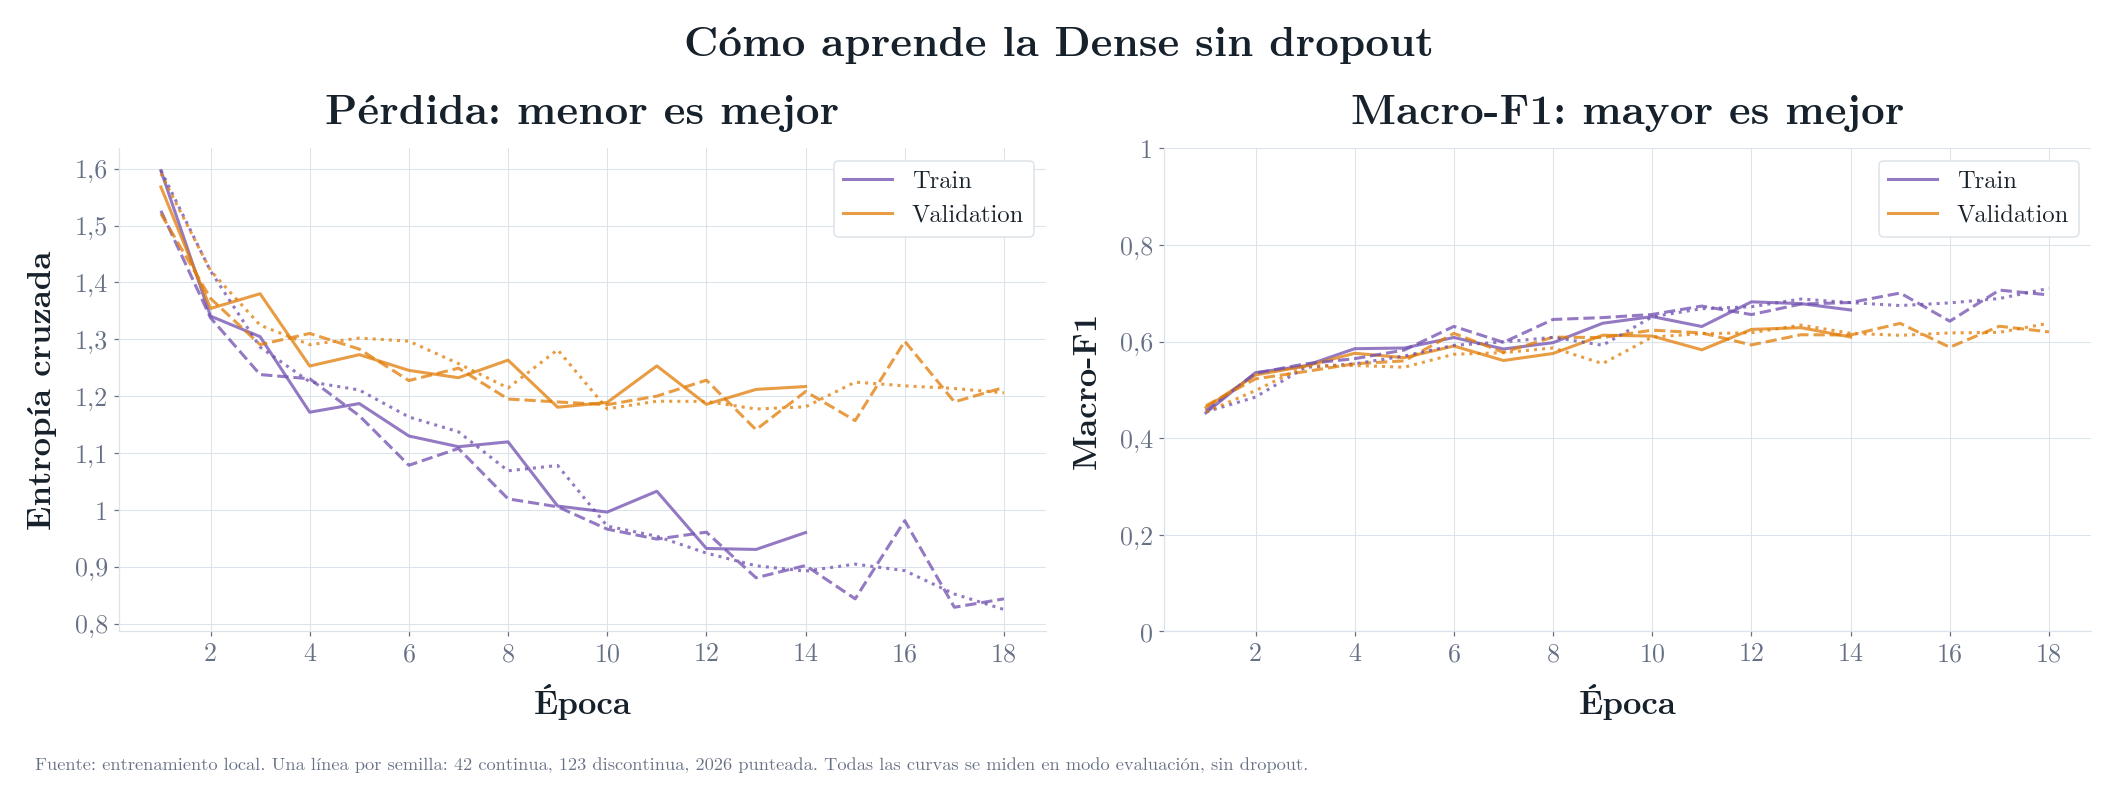

En los checkpoints baseline, macro-F1 medio de train = **0,697** y de validation = **0,635**; diferencia = **0,062**. Esta separación describe generalización en la muestra, no identifica por sí sola su causa.

In [9]:
curves_figure(context, RESULTS)
plt.show()
baseline = records.loc[records.variant.eq('baseline')]
train_f1 = baseline.train_macro_f1.mean()
val_f1 = baseline.validation_macro_f1.mean()
display(Markdown(f"En los checkpoints baseline, macro-F1 medio de train = **{number(train_f1, 3)}** y de validation = **{number(val_f1, 3)}**; diferencia = **{number(train_f1-val_f1, 3)}**. Esta separación describe generalización en la muestra, no identifica por sí sola su causa."))

## 8. Resultados globales y efecto del dropout

Resumimos **las tres semillas**, sin escoger la más favorable. La desviación típica muestral mide variabilidad de entrenamiento; con tres ejecuciones es una estimación limitada, no un intervalo de confianza poblacional.

La comparación de dropout es emparejada: restamos el macro-F1 baseline al de dropout para la misma semilla. Un valor positivo favorece dropout bajo este presupuesto. No cambia la distribución equilibrada del dataset ni sustituye una evaluación final.

Si una variante llega a las treinta épocas, no ampliamos su presupuesto tras ver su resultado: registramos que alcanzó el límite. La comparación mide el efecto de dropout bajo esta regla de entrenamiento, no el mejor rendimiento posible tras ajustar cada variante por separado.

,semillas,macro_F1_media,macro_F1_std,accuracy_media,accuracy_std,tiempo_total_s
variant,,,,,,
baseline,3,"0,635","0,005","0,642","0,006","277,678"
dropout_030,3,"0,49","0,062","0,515","0,054","551,243"


variant,baseline,dropout_030,diferencia_dropout_menos_baseline
seed,,,
42,"0,629","0,448","-0,181"
123,"0,638","0,56","-0,077"
2.026,"0,638","0,461","-0,177"


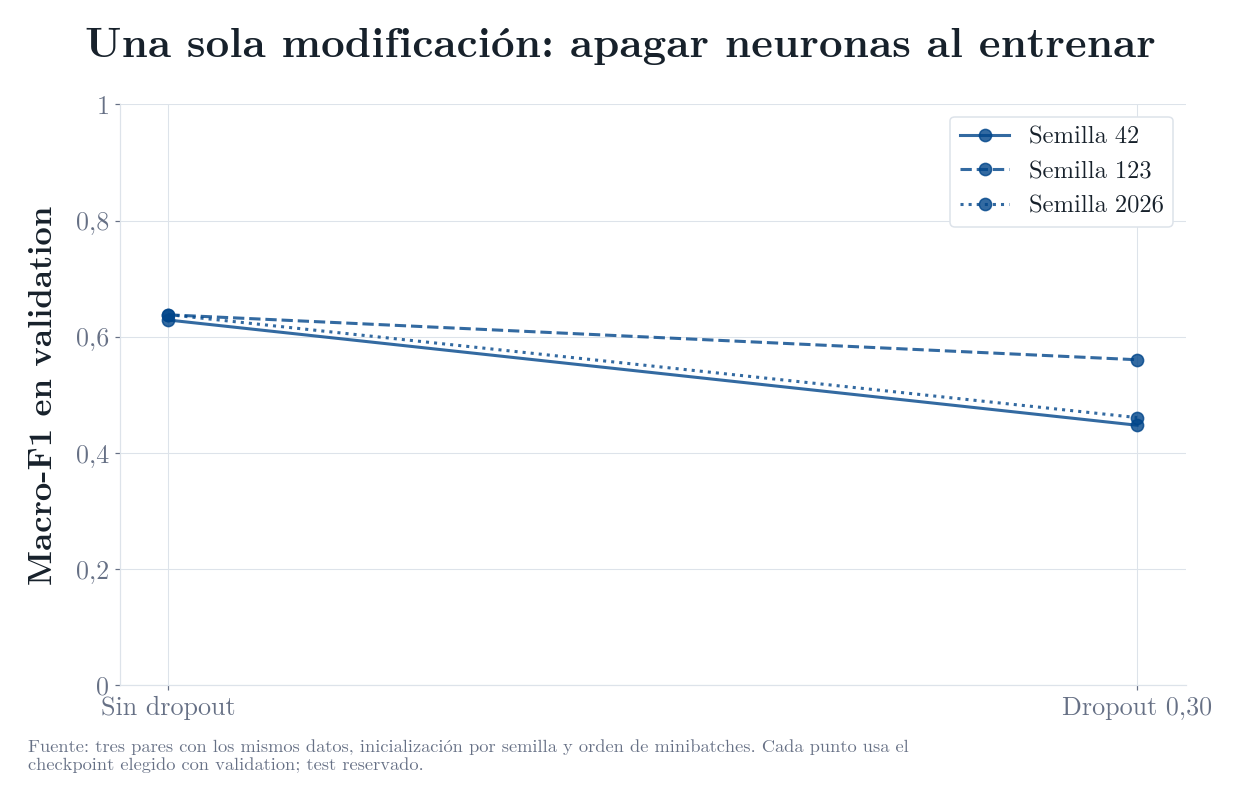

Dropout mejora en **0 de 3 semillas**; diferencia media = **-0,1452** de macro-F1, desviación típica = **0,0588**. La conclusión se limita a esta configuración, estas particiones y estas semillas; no demuestra que dropout ayude siempre.

In [10]:
aggregate = records.groupby('variant').agg(
    semillas=('seed', 'count'), macro_F1_media=('validation_macro_f1', 'mean'),
    macro_F1_std=('validation_macro_f1', 'std'), accuracy_media=('validation_accuracy', 'mean'),
    accuracy_std=('validation_accuracy', 'std'), tiempo_total_s=('train_seconds', 'sum'),
)
display_es(aggregate)
paired = records.pivot(index='seed', columns='variant', values='validation_macro_f1')
paired['diferencia_dropout_menos_baseline'] = paired.dropout_030 - paired.baseline
display_es(paired)
dropout_figure(context, records)
plt.show()
delta = paired['diferencia_dropout_menos_baseline']
positive = int((delta > 0).sum())
display(Markdown(f"Dropout mejora en **{positive} de 3 semillas**; diferencia media = **{number(delta.mean(), 4)}** de macro-F1, desviación típica = **{number(delta.std(), 4)}**. La conclusión se limita a esta configuración, estas particiones y estas semillas; no demuestra que dropout ayude siempre."))
aggregate.to_csv(RESULTS/'analysis_seed_summary.csv')
paired.to_csv(RESULTS/'analysis_dropout_pairs.csv')

## 9. Comparación con los baselines de 03

En 03 medimos mayoría de train y regresión logística de histogramas RGB. La logística utiliza distribución de color sin estructura espacial. Aquí usamos la **semilla 42 fijada de antemano** para ilustrar una Dense concreta, y mostramos por separado la media de las tres semillas. No elegimos la mejor semilla.

Verificamos que los IDs y las etiquetas de validation son exactamente los mismos. Los intervalos siguientes remuestrean **grupos de producto**, manteniendo juntas sus variantes: describen incertidumbre de esa validation para modelos ya entrenados. No incluyen incertidumbre por búsqueda, selección de checkpoint o entrenamiento. Como validation también decide cuándo parar y qué checkpoint guardar, estos resultados son exploratorios y pueden ser optimistas.

In [11]:
from sklearn.metrics import confusion_matrix
predictions = pd.read_csv(RESULTS/'baseline_seed42_predictions.csv.gz', dtype={'article_id':'string', 'group_id':'string'})
assert predictions.article_id.tolist() == rows['validation'].article_id.tolist()
y = rows['validation'].label_id.astype(int).to_numpy()
pred = predictions.predicted_label_id.to_numpy()
classical_predictions = np.load(ROOT/'results/metrics/03_eda/validation_predictions.npz', allow_pickle=False)
assert classical_predictions['article_ids'].tolist() == predictions.article_id.tolist()
np.testing.assert_array_equal(classical_predictions['y'], y)
classical = pd.read_csv(ROOT/'results/metrics/03_eda/validation_baselines.csv').set_index('Modelo')
reference = baseline.loc[baseline.seed.eq(42)].iloc[0]
comparison = classical[['accuracy','macro_F1']].copy()
comparison.loc['Dense, semilla 42'] = [reference.validation_accuracy, reference.validation_macro_f1]
comparison.loc['Dense, media 3 semillas'] = [baseline.validation_accuracy.mean(), baseline.validation_macro_f1.mean()]
display_es(comparison)
ci = reference.validation_group_bootstrap_ci95_macro_f1
display(Markdown(f"Dense semilla 42: **macro-F1 {number(reference.validation_macro_f1, 3)}**, IC bootstrap por grupos 95 % **[{number(ci[0], 3)}, {number(ci[1], 3)}]**. No es un IC sobre toda la distribución del catálogo."))
paired_ci = grouped_intervals(y, pred, predictions.group_id, len(names), draws=300, seed=42,
                              other=classical_predictions['model_1'])
display(Markdown(f"Diferencia Dense42 − logística de color: **{number(reference.validation_macro_f1-classical.loc['Logística de color','macro_F1'], 3)}** de macro-F1; IC emparejado por grupos **[{number(paired_ci[0][1], 3)}, {number(paired_ci[1][1], 3)}]**. Este contraste cambia representación y clasificador, por lo que no aísla solo el efecto de las capas Dense."))
comparison.to_csv(RESULTS/'analysis_classical_comparison.csv')

,accuracy,macro_F1
Modelo,,
Mayoría train,"0,079","0,012"
Logística de color,"0,145","0,138"
"Dense, semilla 42","0,636","0,629"
"Dense, media 3 semillas","0,642","0,635"


Dense semilla 42: **macro-F1 0,629**, IC bootstrap por grupos 95 % **[0,600, 0,650]**. No es un IC sobre toda la distribución del catálogo.

Diferencia Dense42 − logística de color: **0,491** de macro-F1; IC emparejado por grupos **[0,459, 0,518]**. Este contraste cambia representación y clasificador, por lo que no aísla solo el efecto de las capas Dense.

## 10. Qué ocurre en cada clase

En la matriz de confusión, las **filas son clases reales y las columnas predicciones**. La diagonal muestra aciertos. La matriz de proporciones permite comparar clases aunque tengan distinto número de imágenes en validation.

Usamos siempre baseline, semilla 42, para mantener una referencia fija. La tabla por clase incluye soporte: cuántos ejemplos sustentan cada resultado. No justificaremos cambios de etiquetas solo porque la red se equivoque.

**Para leer la tabla:** precisión = de lo que predigo como una clase, cuánto acierto; recall = de los ejemplos reales de esa clase, cuántos encuentro; F1 combina ambos mediante su media armónica. Una clase puede tener mucha precisión y poco recall si el modelo casi nunca la predice. Soporte = número de imágenes reales de esa clase.

,precision,recall,f1-score,support
Clase,,,,
Blouse,"0,347","0,342","0,345",222
Cardigan,"0,487","0,478","0,483",232
Dress,"0,597","0,771","0,673",227
Hoodie,"0,699","0,588","0,639",221
Jacket,"0,538","0,628","0,58",226
Shirt,"0,62","0,694","0,655",245
Shorts,"0,616","0,878","0,724",230
Skirt,"0,728","0,551","0,628",243
Sweater,"0,447","0,477","0,461",237


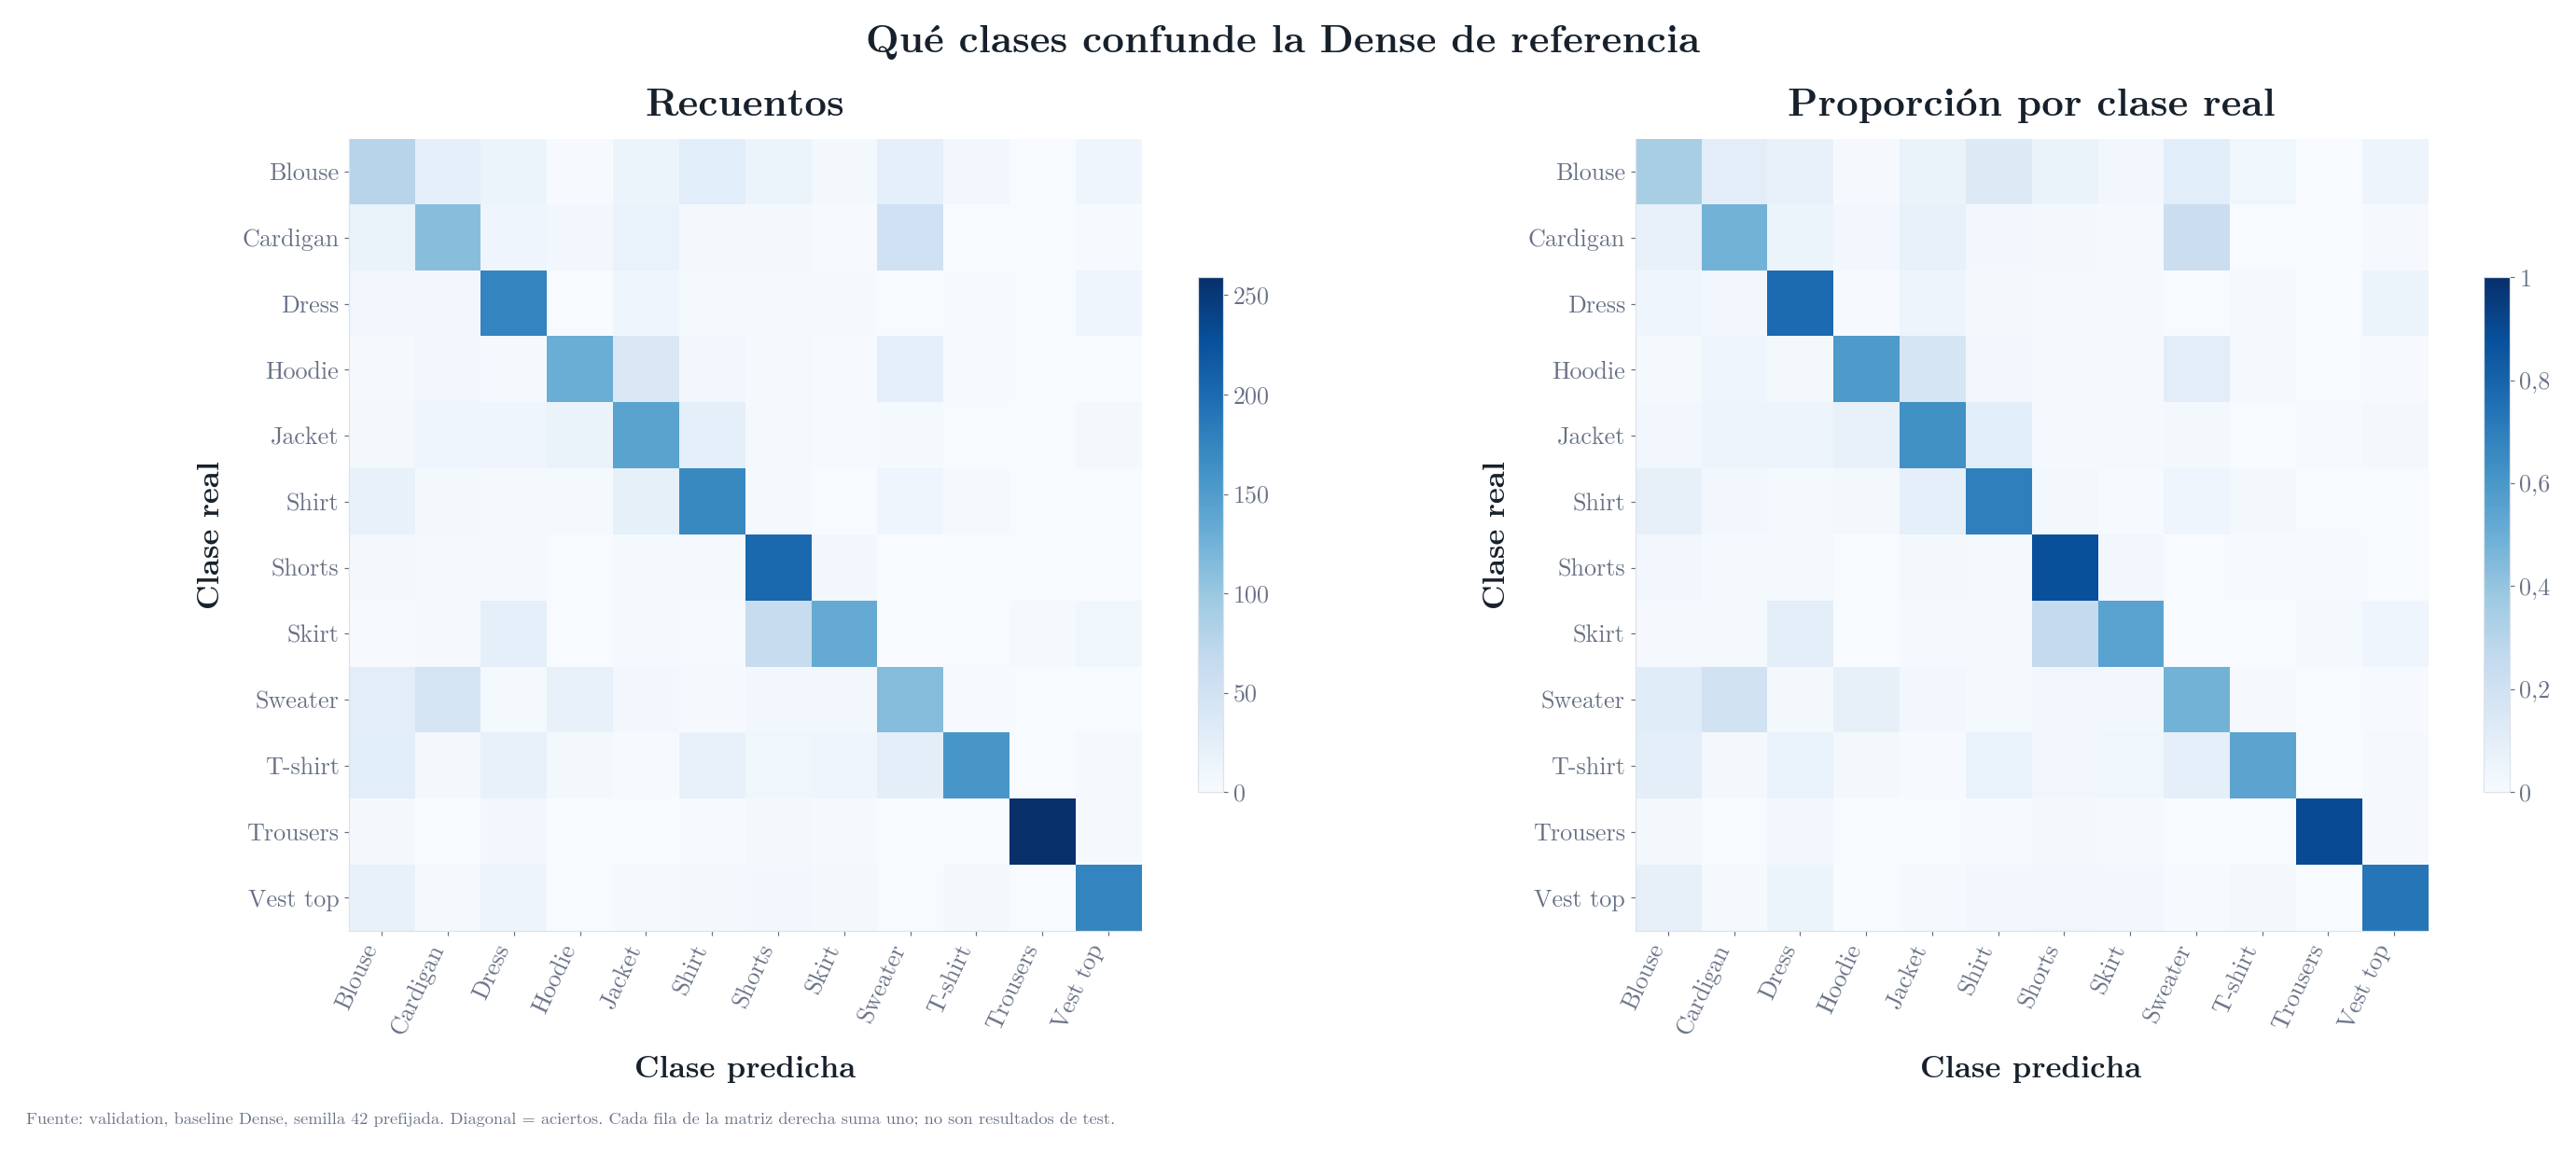

,Real,Predicha,Errores,Proporción de la clase real
83,Skirt,Shorts,62,"0,255"
18,Cardigan,Sweater,52,"0,224"
89,Sweater,Cardigan,46,"0,194"
36,Hoodie,Jacket,37,"0,167"
4,Blouse,Shirt,28,"0,126"
99,T-shirt,Blouse,28,"0,098"
88,Sweater,Blouse,27,"0,114"
107,T-shirt,Sweater,25,"0,087"


In [12]:
report = json.loads((RESULTS/'baseline_seed42_per_class.json').read_text(encoding='utf-8'))
per_class = pd.DataFrame({name: report[name] for name in names}).T
per_class.index.name = 'Clase'
display_es(per_class)
cm = confusion_matrix(y, pred, labels=np.arange(len(names)))
confusion_figure(context, cm)
plt.show()
pairs = pd.DataFrame([
    {'Real':names[i], 'Predicha':names[j], 'Errores':int(cm[i,j]),
     'Proporción de la clase real':float(cm[i,j]/cm[i].sum())}
    for i in range(len(names)) for j in range(len(names)) if i != j
]).sort_values(['Errores','Real','Predicha'], ascending=[False,True,True])
display_es(pairs.head(8))
pairs.to_csv(RESULTS/'analysis_confusion_pairs.csv', index=False)

### ¿La mejora es parecida para todas las clases?

El siguiente gráfico compara el F1 por clase con la logística de color. La altura global de accuracy no basta: puede ocultar clases que siguen siendo difíciles. Aquí identificamos patrones observados; explicaciones como solapamiento de prendas, poses o fondos siguen siendo hipótesis que requieren revisión visual.

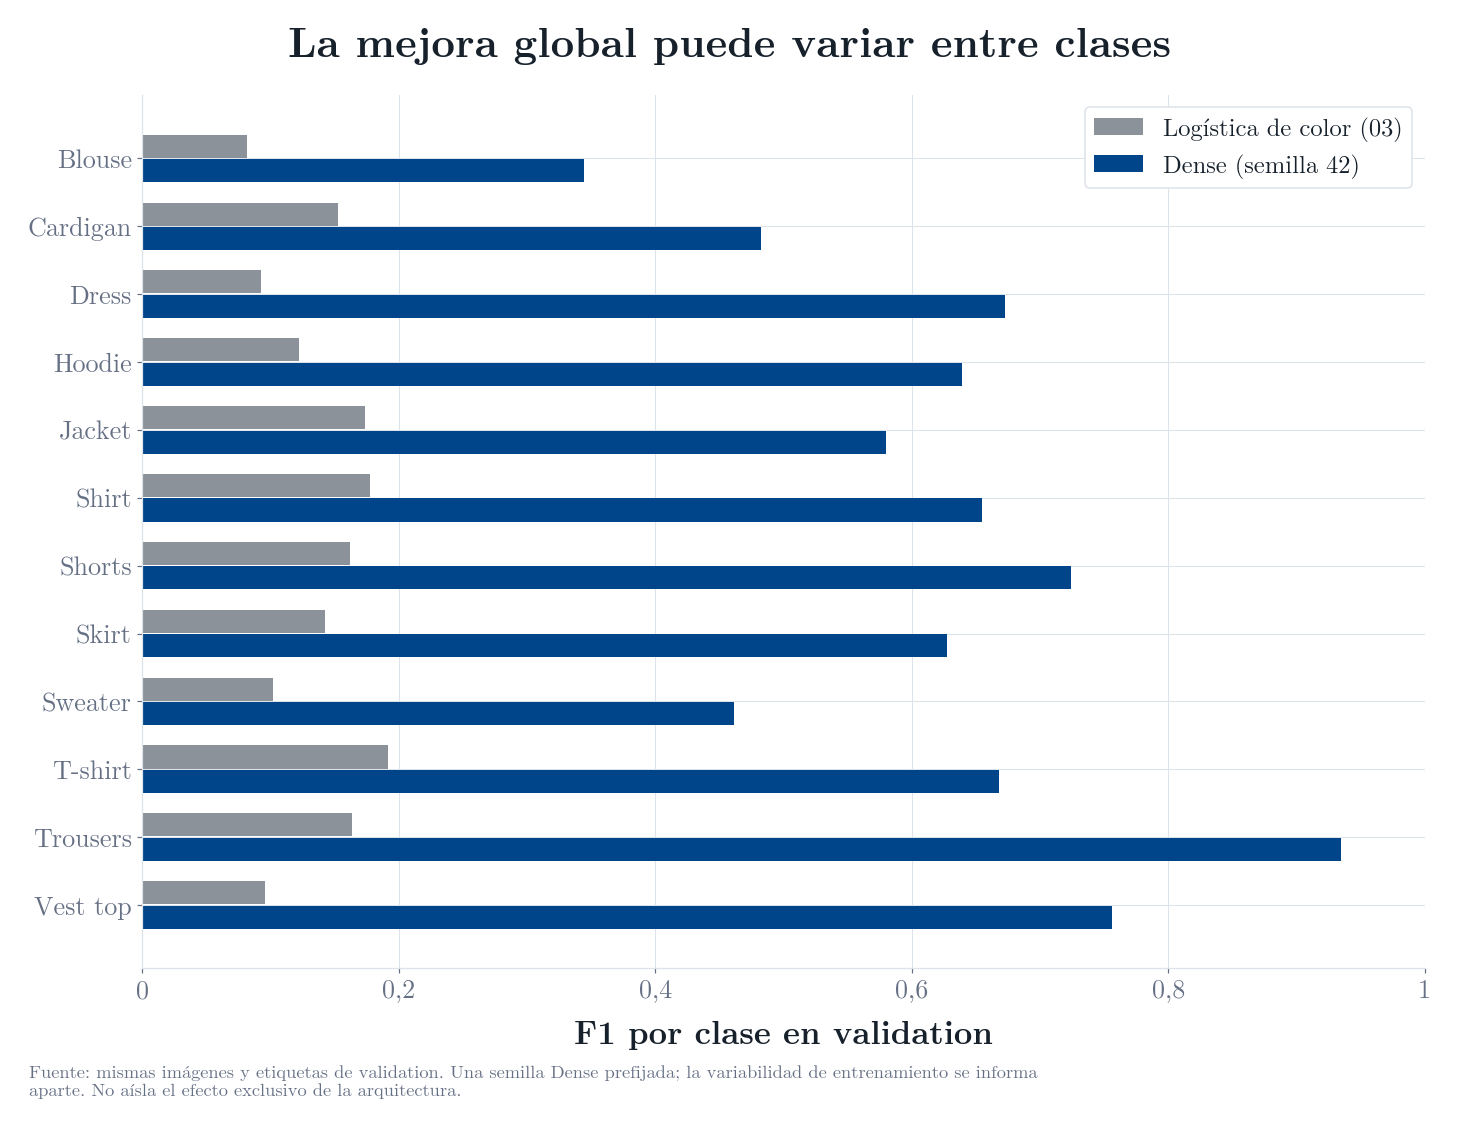

En esta ejecución, mayor F1: **Trousers (0,935)**; menor F1: **Blouse (0,345)**. El error más frecuente en recuentos es **Skirt → Shorts**, con **62 imágenes**. Son observaciones de validation, no propiedades universales de las categorías.

In [13]:
colour_report = pd.read_csv(ROOT/'results/metrics/03_eda/validation_colour_per_class.csv', index_col=0)
per_class_figure(context, report, colour_report)
plt.show()
best_class = per_class['f1-score'].idxmax()
worst_class = per_class['f1-score'].idxmin()
most_confused = pairs.iloc[0]
display(Markdown(f"En esta ejecución, mayor F1: **{best_class} ({number(per_class.loc[best_class,'f1-score'], 3)})**; menor F1: **{worst_class} ({number(per_class.loc[worst_class,'f1-score'], 3)})**. El error más frecuente en recuentos es **{most_confused.Real} → {most_confused.Predicha}**, con **{number(most_confused.Errores)} imágenes**. Son observaciones de validation, no propiedades universales de las categorías."))

### Errores con confianza alta

Mostramos automáticamente los ocho errores con mayor probabilidad softmax, sin escogerlos a mano. Sirven para recordar que **confianza y acierto no son lo mismo**. La softmax no garantiza calibración: una salida de 0,90 no demuestra que el modelo acierte el 90 % de los casos similares.

Esta selección enfatiza fallos llamativos; no representa la frecuencia ni la diversidad de todos los errores. Las posibles etiquetas ambiguas se revisan por separado, no se corrigen automáticamente con la predicción.

En los ejemplos de Sweater → Hoodie conviene revisar la frontera semántica que utiliza el catálogo: una diferencia visual o de denominación puede contribuir al error. Esto abre una pregunta de revisión, no confirma etiquetas equivocadas. Los porcentajes se redondean; un 100,0 % mostrado no significa certeza.

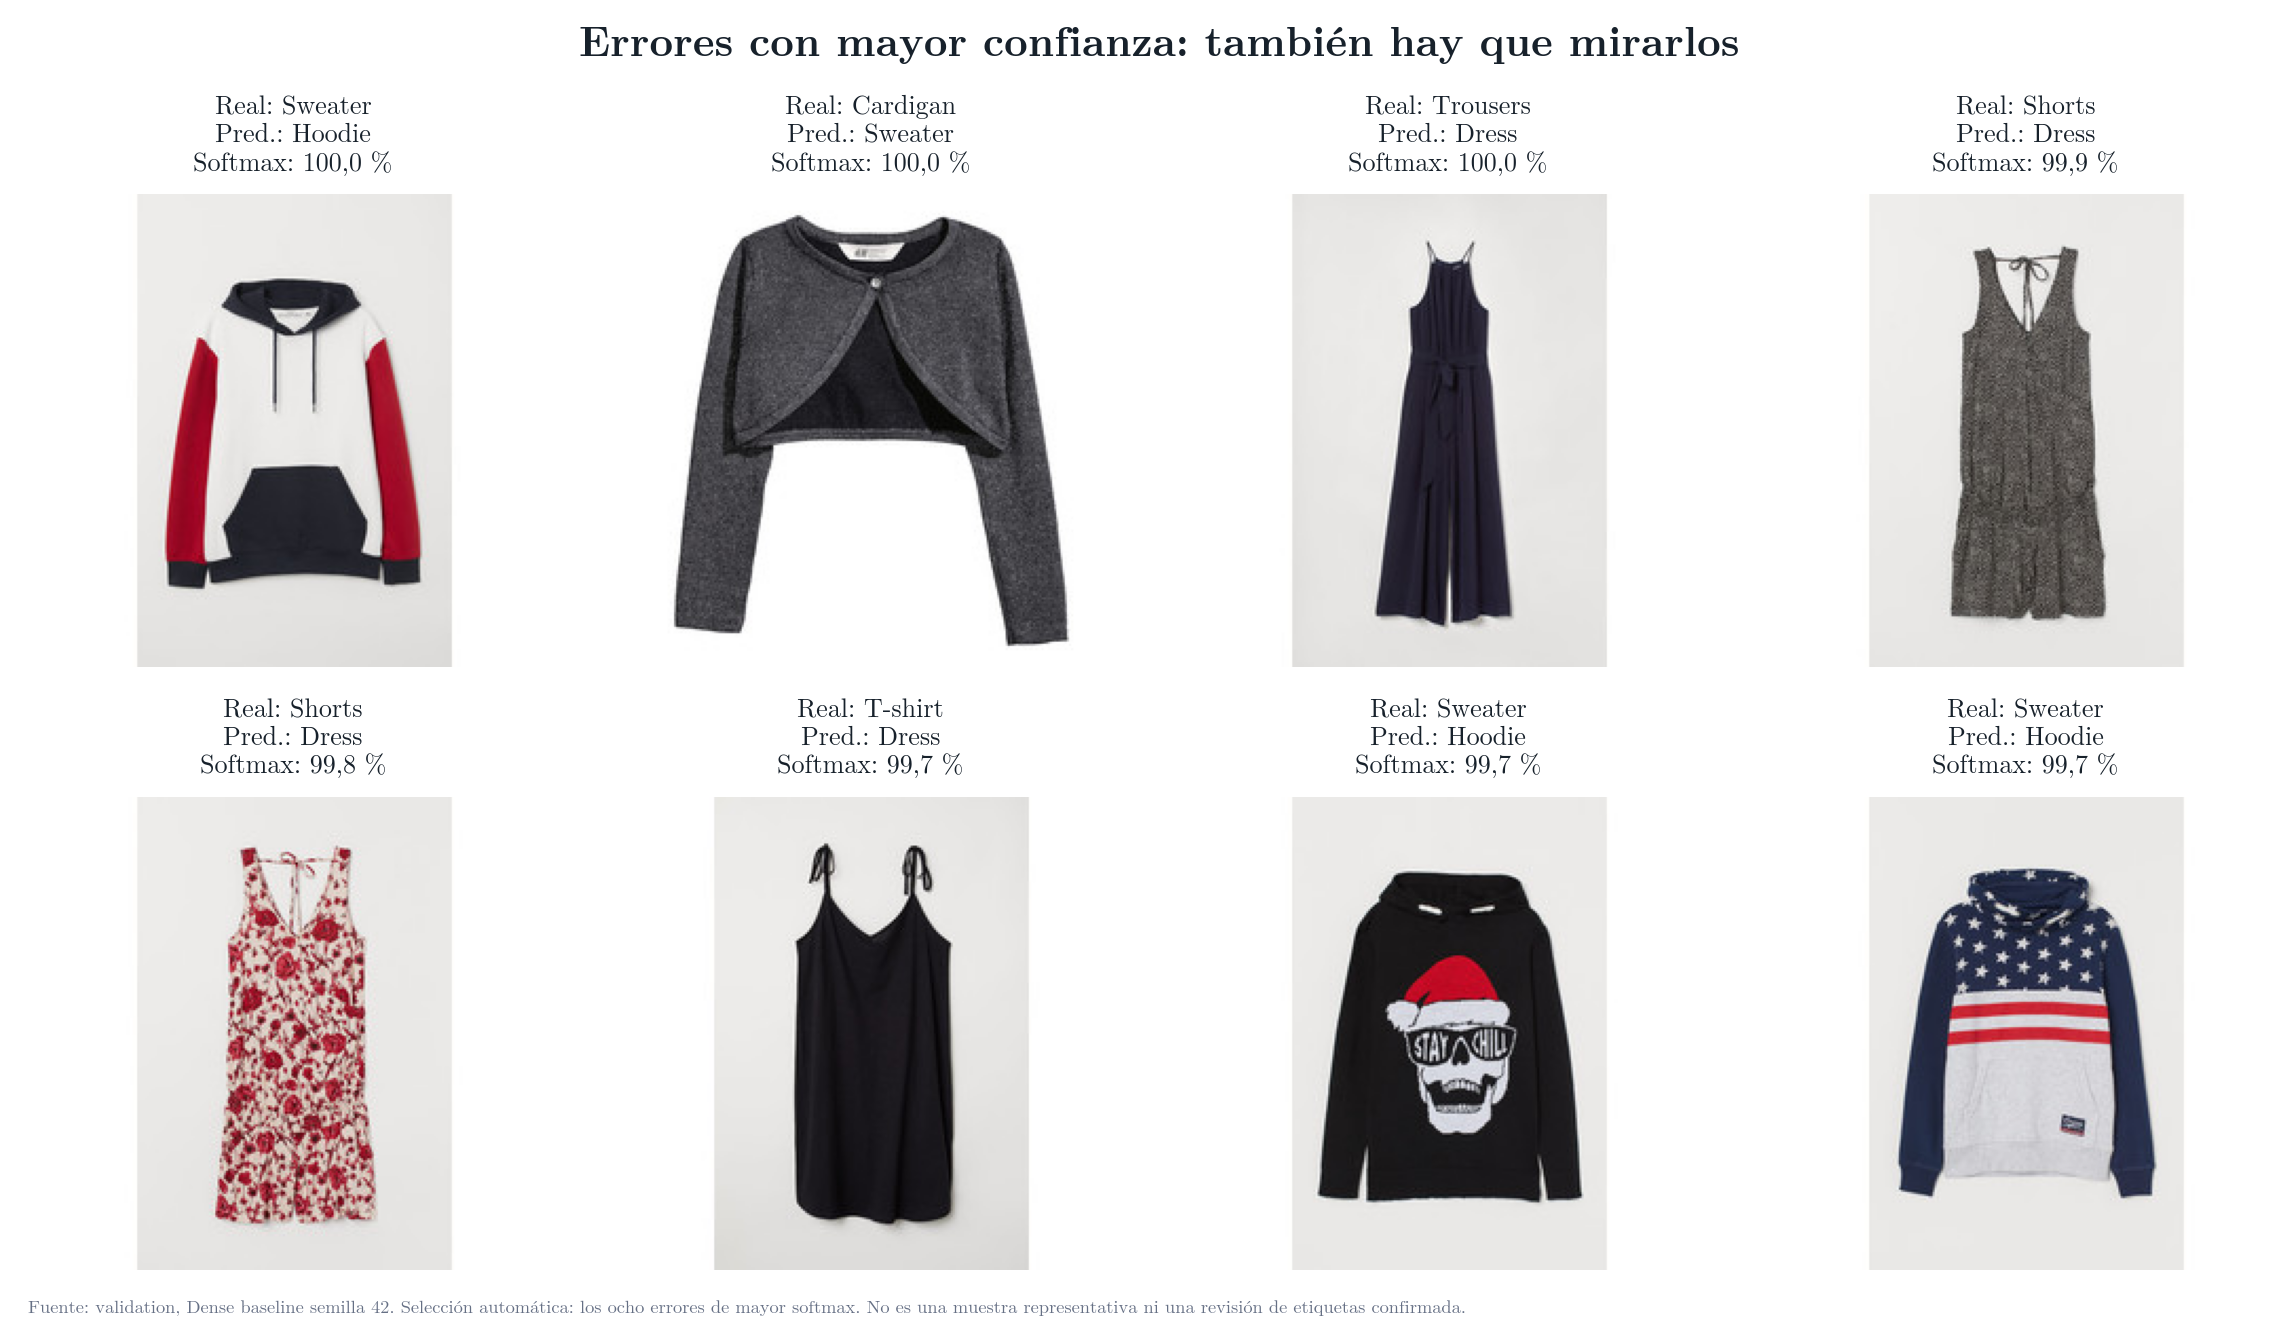

In [14]:
errors_figure(context, predictions)
plt.show()

## 11. Mirar dentro de la Dense sin exagerar la interpretación

Cada neurona de la primera capa tiene un peso por píxel de cada canal. Reorganizamos sus pesos como una cuadrícula de 64×64 y mostramos la media de los tres canales, con una escala común alrededor de cero. **No son fotografías reconstruidas ni explicaciones causales**: es una forma de ver la estructura de los coeficientes aprendidos.

Mostramos las seis primeras neuronas, sin seleccionarlas por apariencia. Después observamos con qué frecuencia la ReLU de cada una de las 80 neuronas es positiva en las primeras 512 imágenes de train. Una neurona inactiva en esa muestra no está necesariamente inactiva en todo el dataset.

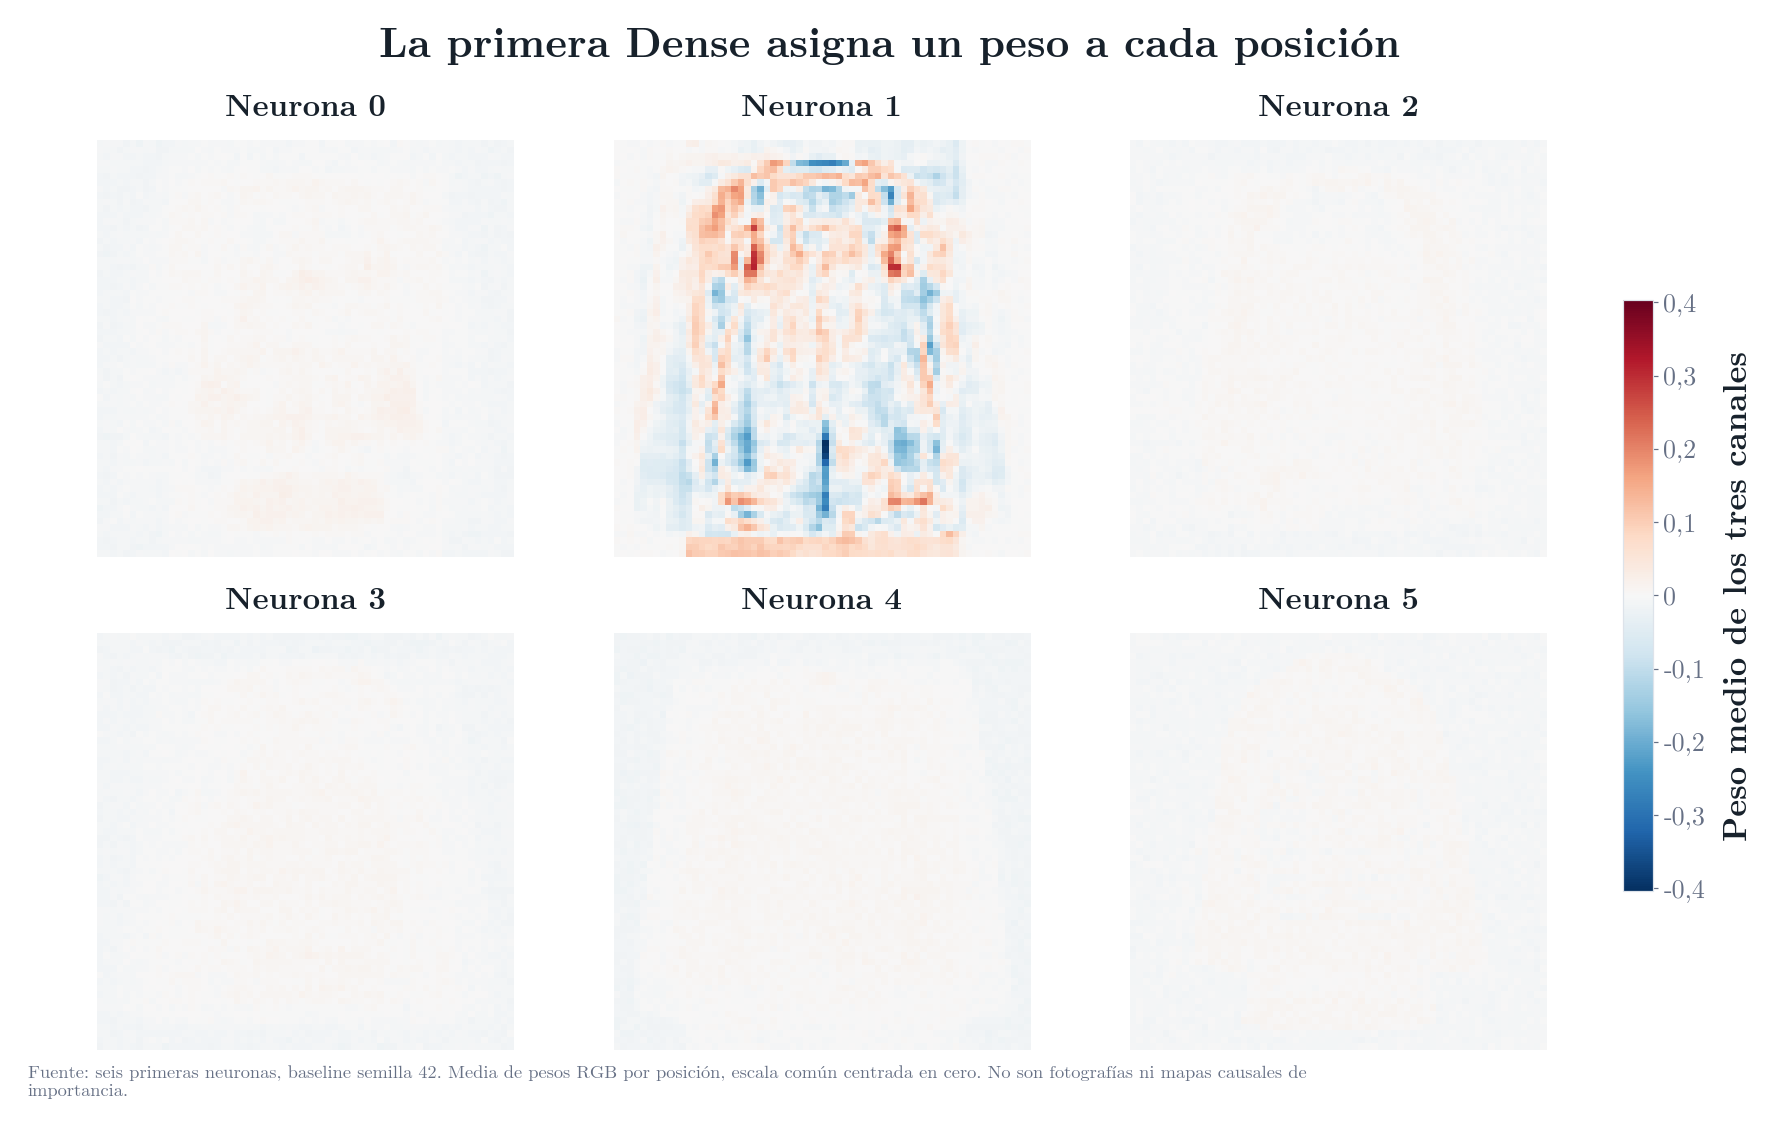

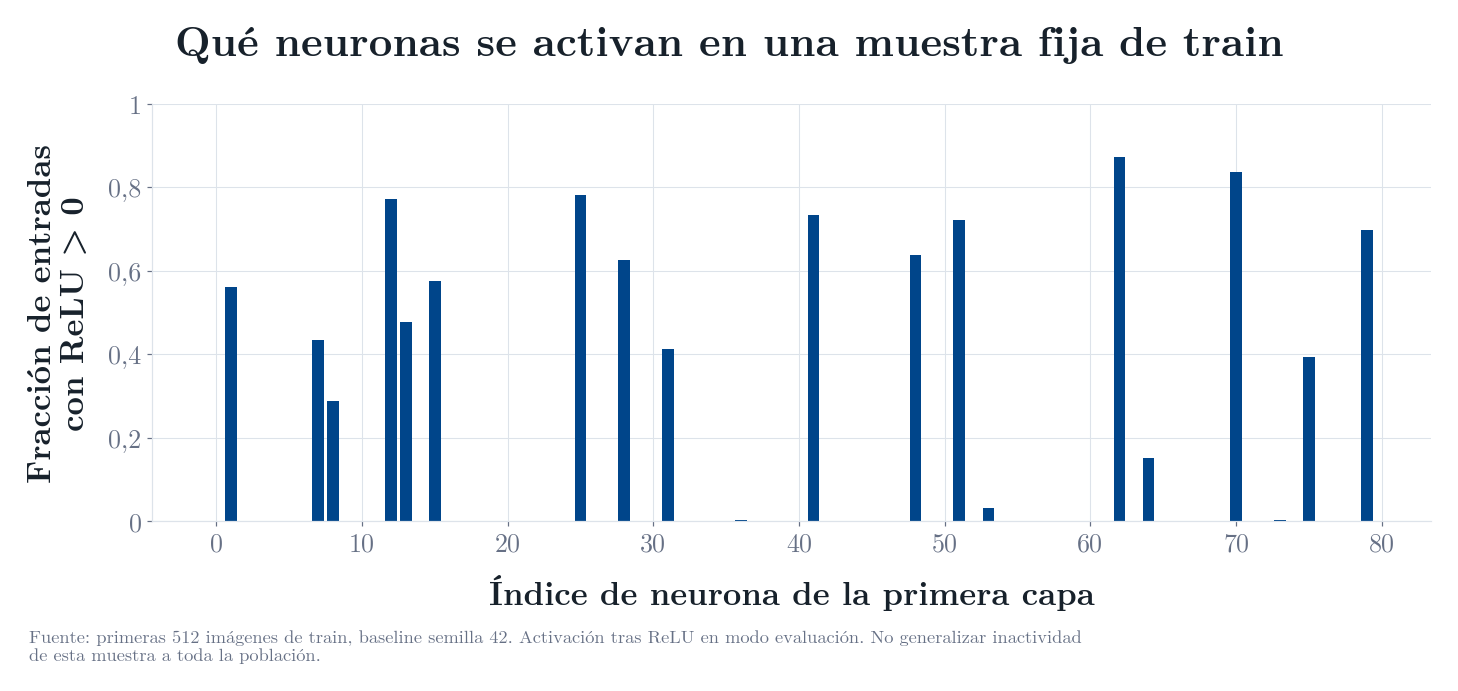

**60 de 80 neuronas** no se activan en esta muestra de 512 imágenes. Es un diagnóstico de esta muestra y checkpoint; no demuestra que sean inútiles en cualquier entrada ni explica por sí solo el efecto del dropout.

In [15]:
checkpoint = ROOT/reference.checkpoint
assert sha256(checkpoint) == reference.checkpoint_sha256
saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
model = model_from_config(config, dropout=0.0)
model.load_state_dict(saved['state_dict'])
model.eval()
weight_figure(context, model)
plt.show()
activation_figure(context, model, tensors)
plt.show()
with torch.inference_mode():
    hidden = torch.relu(model.network[1](tensors['train'][:512].flatten(1)))
    inactive = int((hidden > 0).sum(0).eq(0).sum())
display(Markdown(f"**{inactive} de 80 neuronas** no se activan en esta muestra de 512 imágenes. Es un diagnóstico de esta muestra y checkpoint; no demuestra que sean inútiles en cualquier entrada ni explica por sí solo el efecto del dropout."))

## 12. Coste y reproducibilidad

El tiempo de entrenamiento incluye actualizaciones y evaluación de train/validation por época; excluye lectura y reducción inicial, exportación y análisis posteriores. Informamos el coste de **todas** las semillas y variantes, no solo el modelo ilustrado.

La latencia se mide en CPU, con batch de 32 y datos ya normalizados en RAM, tras calentamiento; es la mediana de tres pasadas. No es la latencia completa de una aplicación que tenga que abrir JPEG.

La memoria es el máximo RSS del proceso Python muestreado cada 50 ms durante entrenamiento: incluye intérprete, librerías y datasets, y puede omitir picos breves. No es memoria exclusiva del modelo ni VRAM. Los FLOPs aproximan multiplicaciones y sumas de capas Dense; no cuentan todas las operaciones.

Las semillas y operaciones deterministas controlan esta ejecución concreta. No garantizan resultados idénticos al cambiar de versión, hardware o CPU a GPU; por eso registramos el entorno y los hashes.

In [16]:
cost = records[['variant','seed','parameters','approx_linear_flops_per_image',
                'train_seconds','inference_ms_per_image','peak_process_rss_bytes']].copy()
cost['RSS proceso (MiB)'] = cost.pop('peak_process_rss_bytes')/1024**2
display_es(cost)
display(Markdown(f"**Coste total de las seis ejecuciones:** {number(records.train_seconds.sum()/60, 2)} minutos, más preparación y análisis. Hardware: `{summary['hardware']['processor']}`, CPU con {summary['hardware']['threads_used']} hilos."))
provenance = pd.DataFrame({
    'Elemento': ['Dataset', 'Configuración', 'Código de modelo', 'Código de entrenamiento', 'PyTorch', 'Checkpoint ilustrado'],
    'Referencia': [summary['dataset_run'], summary['identity']['sources']['config/dense_baseline_v1.json'],
                  summary['identity']['sources']['src/models/dense.py'],
                  summary['identity']['sources']['src/training/dense_experiment.py'],
                  summary['identity']['versions']['torch'], str(reference.checkpoint)],
})
display(provenance)
assert parameter_count(model) == 986_108
assert int(saved['epoch']) == int(reference.selected_epoch)
display(Markdown('**Verificado:** seis ejecuciones terminadas, checkpoints reabiertos y reproducibles, IDs alineados con 03, cero fotografías ni predicciones de test. Pesos y cachés se conservan en local; métricas, figuras y salidas del notebook documentan el experimento.'))

,variant,seed,parameters,approx_linear_flops_per_image,train_seconds,inference_ms_per_image,RSS proceso (MiB)
0,baseline,42,986.108,1.971.968,"72,103","0,036","1.344,352"
1,baseline,123,986.108,1.971.968,"100,247","0,057","1.348,266"
2,baseline,2.026,986.108,1.971.968,"105,327","0,054","1.348,648"
3,dropout_030,42,986.108,1.971.968,"189,782","0,047","1.355,457"
4,dropout_030,123,986.108,1.971.968,"172,093","0,046","1.355,395"
5,dropout_030,2.026,986.108,1.971.968,"189,368","0,043","1.355,488"


**Coste total de las seis ejecuciones:** 13,82 minutos, más preparación y análisis. Hardware: `Intel64 Family 6 Model 165 Stepping 2, GenuineIntel`, CPU con 4 hilos.

,Elemento,Referencia
0,Dataset,20261119T140252-527f781b
1,Configuración,1e2e1ac957638da2a2a988d34f77ac51157e959dace865...
2,Código de modelo,3cdc051da69ca19544b10d45cfe88a4f702f28347c1a72...
3,Código de entrenamiento,699a91c1df4e9b5099bc95d7d7b2ee4fc287ed999eaed1...
4,PyTorch,2.7.1+cpu
5,Checkpoint ilustrado,results\models\04_dense\c6cf19b36282fd2e\basel...


**Verificado:** seis ejecuciones terminadas, checkpoints reabiertos y reproducibles, IDs alineados con 03, cero fotografías ni predicciones de test. Pesos y cachés se conservan en local; métricas, figuras y salidas del notebook documentan el experimento.

## 13. Qué podemos concluir y qué queda pendiente

Las conclusiones numéricas se generan a partir de los resultados anteriores. El objetivo es distinguir evidencia, interpretación y siguiente paso.

In [17]:
logistic_f1 = classical.loc['Logística de color','macro_F1']
display(Markdown(f"""
- **Baseline neuronal:** macro-F1 medio de validation **{number(val_f1, 3)} ± {number(baseline.validation_macro_f1.std(), 3)}** entre tres semillas; accuracy media **{percent(baseline.validation_accuracy.mean())}**. El símbolo ± indica desviación típica entre semillas.
- **Respecto a 03:** la Dense42 obtiene **{number(reference.validation_macro_f1, 3)}** frente a **{number(logistic_f1, 3)}** de la logística de color. El contraste combina cambios de representación y clasificador.
- **Dropout 0,30:** diferencia media emparejada **{number(delta.mean(), 4)}** de macro-F1; mejora en **{positive}/3 semillas**. No extrapolamos a otras arquitecturas ni a otros valores de dropout.
- **Generalización:** separación media train − validation de **{number(train_f1-val_f1, 3)}** en macro-F1 para el baseline. Debe leerse junto a las curvas y los errores, no como una explicación causal aislada.
- **Siguiente paso:** notebook 05, CNN RGB64 con presupuesto de parámetros comparable y las mismas particiones. Hasta entonces **H1 no está resuelta**.
"""))


- **Baseline neuronal:** macro-F1 medio de validation **0,635 ± 0,005** entre tres semillas; accuracy media **64,2 %**. El símbolo ± indica desviación típica entre semillas.
- **Respecto a 03:** la Dense42 obtiene **0,629** frente a **0,138** de la logística de color. El contraste combina cambios de representación y clasificador.
- **Dropout 0,30:** diferencia media emparejada **-0,1452** de macro-F1; mejora en **0/3 semillas**. No extrapolamos a otras arquitecturas ni a otros valores de dropout.
- **Generalización:** separación media train − validation de **0,062** en macro-F1 para el baseline. Debe leerse junto a las curvas y los errores, no como una explicación causal aislada.
- **Siguiente paso:** notebook 05, CNN RGB64 con presupuesto de parámetros comparable y las mismas particiones. Hasta entonces **H1 no está resuelta**.


### Límites y conexión con el informe

Esta es una evaluación de **validation utilizada durante el desarrollo**, no el resultado final. Conservamos el test cerrado. La selección de doce clases y el equilibrio son exploratorios; no inferimos rendimiento sobre el catálogo real. Tres semillas y una validation no abarcan toda la incertidumbre. No hemos ejecutado búsquedas de optimizador, profundidad, pesos de clase, aumentos ni todos los experimentos anunciados en la estructura inicial.

Para el resumen inicial del informe —máximo tres páginas según el correo del profesor— bastan la pregunta, el protocolo, el resultado medio con su variabilidad, una limitación y el siguiente contraste. Las seis historias y detalles técnicos pueden ir al anexo o permanecer en este notebook.

**Referencias de apoyo:** materiales de clase sobre FeedForward y entropía cruzada; [CrossEntropyLoss de PyTorch](https://docs.pytorch.org/docs/2.7/generated/torch.nn.CrossEntropyLoss.html) y [reproducibilidad de PyTorch](https://docs.pytorch.org/docs/2.7/notes/randomness.html). Las decisiones de tamaño, presupuesto y ablación son nuestras; no son instrucciones literales del profesor.